# Aula 05 · Vídeo 4 — Lab E2E: Pipeline LGPD-Compliant com Audit Trail e Purga Seletiva

> **Disciplina:** Segurança, Guardrails e Conformidade para LLMs · **Caso condutor:** Banco **Aurora** / **Aurora Assist**
> **Tipo:** conceitual **+** prático (E2E) · **Doc 04:** Figura 1 (pipeline integrado), §4 (art. 37), §10 (esquecimento)

## 🎯 Objetivos
- **Consumir** a stack compliant (não treinar modelo): consentimento → minimização → registro de tratamento (WORM) → purga seletiva.
- Ver a **recusa de decisão automatizada de crédito** (GDPR art. 22) e a **transparência** do EU AI Act.
- Coletar métricas e gerar `reports/` (painel de conformidade, estilo Azure Workbooks).

> [!WARNING]
> ⚠️ **Uso ético.** Dados sintéticos; uso **defensivo e didático** (Doc 04, §12).

## 0. Suba a stack (uma vez) — ou rode offline

```bash
uv run task up                       # docker compose up -d (rag-api + consent-service + postgres + presidio + qdrant + purge-worker + ollama)
docker compose exec ollama ollama pull llama3.1:8b
uv run task seed-data                # gera os datasets sintéticos (seed fixa)
```

Este notebook detecta automaticamente se a **rag-api** está no ar (`AURORA_RAG_URL`). Se **não** estiver, ele sobe o **mesmo app in-process** (offline, backend `stub`), de modo que *Restart & Run All* sempre funcione.

In [1]:
import os, json
from pathlib import Path
import httpx

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
os.chdir(ROOT)

RAG_URL = os.getenv('AURORA_RAG_URL', 'http://localhost:8000')
try:
    LIVE = httpx.get(f'{RAG_URL}/health', timeout=2.0).status_code == 200
except Exception:
    LIVE = False

if LIVE:
    client = httpx.Client(base_url=RAG_URL, timeout=30.0)
    print('Modo: LIVE (rag-api no ar em', RAG_URL, ')')
else:
    # Offline: sobe o app in-process com backend stub (determinístico, sem nuvem).
    os.environ.setdefault('LLM_BACKEND', 'stub')
    os.environ.setdefault('VECTOR_STORE', 'memory')
    os.environ.setdefault('CONSENT_SERVICE_URL', 'http://consent-service.invalid')
    os.environ.setdefault('MINIMIZE_PII', 'true')
    os.environ.setdefault('ENFORCE_CONSENT', 'true')
    os.environ.setdefault('TREATMENT_LOG_PATH', str(ROOT / 'reports' / 'nb_treatment_chain.jsonl'))
    Path(os.environ['TREATMENT_LOG_PATH']).unlink(missing_ok=True)
    import sys
    sys.path.insert(0, str(ROOT))
    from fastapi.testclient import TestClient
    from app.main import app
    client = TestClient(app)
    print('Modo: OFFLINE (app in-process, backend stub)')

Modo: OFFLINE (app in-process, backend stub)


## 1. Consentimento (art. 7) — base legal antes de tratar

O titular concede consentimento **granular** por finalidade. Sem base legal adequada, o tratamento é bloqueado.

In [2]:
SUBJECT = 'cli-90432'
r = client.post('/consent', json={'subject_id': SUBJECT,
                                   'purposes': {'consulta_saldo': True, 'faq_produtos': True,
                                                'treino_modelo': False}})
print('Consentimento registrado (v%s):' % r.json()['version'], r.json()['purposes'])

Consentimento registrado (v1): {'consulta_saldo': True, 'faq_produtos': True, 'treino_modelo': False}


## 2. Índice RAG por titular — preparando a purga seletiva

Indexamos documentos de atendimento atrelados ao `subject_id` (Doc 04, §10). Alguns contêm PII sintética, ilustrando o risco de vetorizar dado pessoal.

In [3]:
corpus_path = ROOT / 'data' / 'rag_corpus' / 'rag_corpus.jsonl'
docs = []
if corpus_path.exists():
    docs = [json.loads(l) for l in corpus_path.read_text(encoding='utf-8').splitlines() if l.strip()]
else:
    docs = [
        {'doc_id': 'inst-1', 'subject_id': 'banco', 'text': 'Horários e tarifas das agências.'},
        {'doc_id': 'a-1', 'subject_id': SUBJECT, 'text': 'Atendimento: 2a via de cartão.'},
    ]
indexed = 0
for d in docs[:20]:
    client.post('/rag/index', json={'doc_id': d['doc_id'], 'subject_id': d['subject_id'],
                                     'text': d['text']})
    indexed += 1
print(f'{indexed} documentos indexados no vector store.')

20 documentos indexados no vector store.


## 3. Chat conforme — minimização + transparência + registro de tratamento

Cada `/chat` minimiza PII no prompt (art. 6, V), informa que é uma IA (EU AI Act art. 50) e emite um **registro de tratamento** imutável (art. 37).

In [4]:
resp = client.post('/chat', json={'message': 'Meu CPF é 529.982.247-25, qual a taxa do CDB?',
                                   'subject_id': SUBJECT, 'purpose': 'faq_produtos', 'top_k': 3})
body = resp.json()
print('Resposta (trecho):', body['answer'][:140], '...')
print('PII minimizada no prompt:', body['minimized_entities'])
print('Registro de tratamento nº:', body['treatment_index'])
print('Nível EU AI Act:', body['ai_act_tier'], '| residência:', body['data_residency'])
assert '529.982.247-25' not in body['answer'], 'CPF não pode vazar!'
print('\nOK: o CPF não aparece na resposta (minimização + egresso).')

Resposta (trecho): Você está conversando com o Aurora Assist, uma inteligência artificial do Banco Aurora.

Sou o Aurora Assist e posso ajudar com dúvidas sobr ...
PII minimizada no prompt: ['BR_CPF']
Registro de tratamento nº: 0
Nível EU AI Act: limited | residência: brazil-south

OK: o CPF não aparece na resposta (minimização + egresso).


## 4. Recusa de decisão automatizada de crédito (GDPR art. 22 / LGPD art. 20)

O Aurora Assist **não decide** crédito automaticamente — encaminha para revisão humana, preservando o nível de risco **limitado**.

In [5]:
credito = client.post('/chat', json={'message': 'Aprove meu empréstimo de R$ 50 mil agora.',
                                      'subject_id': SUBJECT, 'purpose': 'faq_produtos', 'top_k': 0}).json()
print('Bloqueado?', credito['blocked'], '| motivo:', credito['block_reason'])
print('Resposta:', credito['answer'])

Bloqueado? True | motivo: automated_credit_decision
Resposta: Não realizo decisões automatizadas sobre crédito. Sua solicitação será encaminhada para análise humana, conforme a LGPD (art. 20) e o GDPR (art. 22). Você tem direito a revisão por uma pessoa.


## 5. Direito ao esquecimento — purga seletiva (art. 18, VI)

O titular exerce o direito à exclusão. A rag-api purga **apenas** os vetores dele, preservando os institucionais e de outros titulares.

In [6]:
antes = client.post('/dsr/access', json={'subject_id': SUBJECT}).json()
print('Antes: documentos do titular no índice =', len(antes['indexed_documents']))

erasure = client.post('/dsr/erasure', json={'subject_id': SUBJECT}).json()
print('Purga seletiva:', erasure['deleted_count'], 'vetor(es) removido(s).')

depois = client.post('/dsr/access', json={'subject_id': SUBJECT}).json()
print('Depois: documentos do titular no índice =', len(depois['indexed_documents']))
print('\nLimite honesto:', erasure['model_unlearning_note'][:120], '...')

Antes: documentos do titular no índice = 0
Purga seletiva: 0 vetor(es) removido(s).
Depois: documentos do titular no índice = 0

Limite honesto: Purga na camada de RECUPERAÇÃO concluída. O conhecimento absorvido em fine-tuning NÃO é endereçável por delete (Doc 04,  ...


## 6. Painel de conformidade + integridade da trilha (art. 37)

Coletamos o resumo de conformidade e verificamos a **integridade da hash chain** do registro de tratamento — evidência para uma auditoria simulada.

Nível EU AI Act: limited | alto risco? False
Residência de dados: brazil-south
Registros de tratamento: 2
Integridade da trilha (WORM): True


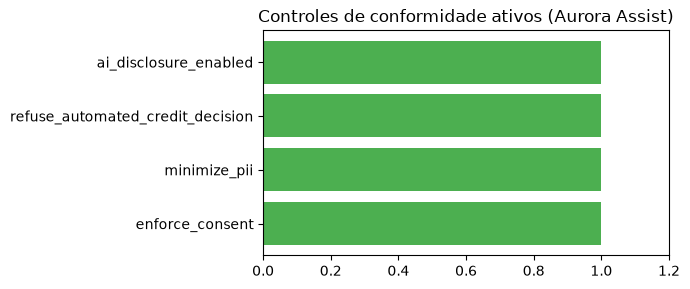

In [7]:
import matplotlib.pyplot as plt

summary = client.get('/compliance/summary').json()
records = client.get('/treatment/records').json()

print('Nível EU AI Act:', summary['ai_act_tier'], '| alto risco?', summary['high_risk'])
print('Residência de dados:', summary['data_residency_region'])
print('Registros de tratamento:', summary['treatment_records'])
print('Integridade da trilha (WORM):', summary['treatment_chain_integrity'])

controls = summary['controls']
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(controls.keys()), [1 if v else 0 for v in controls.values()],
        color=['#4caf50' if v else '#e53935' for v in controls.values()])
ax.set_xlim(0, 1.2); ax.set_title('Controles de conformidade ativos (Aurora Assist)')
plt.tight_layout(); plt.show()

In [8]:
# Gera o relatório de conformidade em reports/ (estilo Azure Workbook).
reports = ROOT / 'reports'
reports.mkdir(exist_ok=True)
out = reports / 'compliance_summary.json'
out.write_text(json.dumps({'summary': summary, 'chain_integrity': records['chain_integrity'],
                           'treatment_records': records['records']},
                          ensure_ascii=False, indent=2), encoding='utf-8')
print('Relatório escrito em', out.relative_to(ROOT))

Relatório escrito em reports\compliance_summary.json


## ✅ Resumo e gancho para a Aula 06

Vimos o **pipeline LGPD-compliant** ponta a ponta: **consentimento** (art. 7) → **minimização** (art. 6, V) → **transparência** (EU AI Act) → **registro de tratamento** imutável (art. 37) → **purga seletiva** (art. 18, VI), com **recusa de decisão automatizada** (art. 22). Conformidade é a **leitura jurídica das defesas técnicas** já construídas.

Mas conformidade precisa ser **mantida** dia após dia. ➡️ **Aula 06 — LLMOps: Governança de Dados e Monitoramento Contínuo**: *drift*, OpenTelemetry, SLOs e observabilidade para manter qualidade, custo e conformidade sob controle em produção.